In [1]:
import math
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda

ROOT = Path.cwd()
OUTPUT = ROOT / "asd_2d_results"
OUTPUT.mkdir(parents=True, exist_ok=True)

J_asd = 1.0
q0_asd = np.pi / 4
D_asd = J_asd * np.tan(q0_asd)
J2_asd = J_asd / (4 * np.cos(q0_asd))
Bz_asd = 0.0

N_REPLICAS_ASD = 4
N_SAMPLES_ASD = 512
DT_ASD = 0.025
SAMPLE_EVERY_ASD = 5
T_ASD = 0.1

BLOCK_ASD = (8, 8, 1)

print("CUDA available:", cuda.is_available())
print("Output:", OUTPUT)

CUDA available: True
Output: /home/senji77/akhyar/research/notebooks/ANSW/asd_2d_results


In [2]:
path_dmi = ROOT / "production_dmi_x" / "spins_dmi_latest.npy"
fr_candidates = [
    ROOT / "spins_frustration_latest.npy",
    ROOT / "production_frustration" / "spins_frustration_latest.npy"
]

path_fr = next((p for p in fr_candidates if p.exists()), None)

if not path_dmi.exists():
    raise FileNotFoundError(path_dmi)

if path_fr is None:
    raise FileNotFoundError("spins_frustration_latest.npy not found in ANSW")

spins_dmi_saved = np.load(path_dmi)
spins_fr_saved = np.load(path_fr)

if spins_dmi_saved.shape[1:] != spins_fr_saved.shape[1:]:
    raise ValueError("DMI-x and frustration lattice shapes do not match")

if spins_dmi_saved.shape[1] != spins_dmi_saved.shape[2]:
    raise ValueError("Expected square 2D lattice")

L_asd = spins_dmi_saved.shape[1]

rng_asd = np.random.default_rng(2026)
indices_dmi = rng_asd.choice(len(spins_dmi_saved), size=N_REPLICAS_ASD, replace=False)
indices_fr = rng_asd.choice(len(spins_fr_saved), size=N_REPLICAS_ASD, replace=False)

initial_spins = {
    "dmi": np.ascontiguousarray(spins_dmi_saved[indices_dmi], dtype=np.float32),
    "frustration": np.ascontiguousarray(spins_fr_saved[indices_fr], dtype=np.float32)
}

for model, path in [
    ("dmi", ROOT / "production_dmi_x" / "progress_dmi.npz"),
    ("frustration", ROOT / "progress_frustration.npz")
]:
    if path.exists():
        with np.load(path) as progress:
            last_T = float(progress["T"][-1])
        print(model, "saved T =", last_T)
        if not np.isclose(last_T, T_ASD, atol=1e-6):
            raise ValueError(f"{model} snapshot is from T={last_T}, not {T_ASD}")
    else:
        print(model, "temperature metadata not found: verify the final snapshot is T=0.1")

print("DMI-x file:", path_dmi)
print("Frustration file:", path_fr)
print("Lattice:", L_asd, "x", L_asd)
print("Replicas per model:", N_REPLICAS_ASD)

dmi saved T = 0.1
frustration saved T = 0.1
DMI-x file: /home/senji77/akhyar/research/notebooks/ANSW/production_dmi_x/spins_dmi_latest.npy
Frustration file: /home/senji77/akhyar/research/notebooks/ANSW/spins_frustration_latest.npy
Lattice: 64 x 64
Replicas per model: 4


In [3]:
@cuda.jit
def rhs_gpu(spins, derivatives, model_id, J, J2, D, Bz):
    x, y, r = cuda.grid(3)

    nx = spins.shape[1]
    ny = spins.shape[2]

    if r >= spins.shape[0] or x >= nx or y >= ny:
        return

    xp = (x + 1) % nx
    xm = (x - 1 + nx) % nx
    yp = (y + 1) % ny
    ym = (y - 1 + ny) % ny

    sx = spins[r, x, y, 0]
    sy = spins[r, x, y, 1]
    sz = spins[r, x, y, 2]

    hx = J * (
        spins[r, xp, y, 0] + spins[r, xm, y, 0]
        + spins[r, x, yp, 0] + spins[r, x, ym, 0]
    )

    hy = J * (
        spins[r, xp, y, 1] + spins[r, xm, y, 1]
        + spins[r, x, yp, 1] + spins[r, x, ym, 1]
    )

    hz = J * (
        spins[r, xp, y, 2] + spins[r, xm, y, 2]
        + spins[r, x, yp, 2] + spins[r, x, ym, 2]
    ) + Bz

    if model_id == 0:
        hy += D * (spins[r, xp, y, 2] - spins[r, xm, y, 2])
        hz -= D * (spins[r, xp, y, 1] - spins[r, xm, y, 1])
    else:
        xpp = (x + 2) % nx
        xmm = (x - 2 + nx) % nx

        hx -= J2 * (spins[r, xpp, y, 0] + spins[r, xmm, y, 0])
        hy -= J2 * (spins[r, xpp, y, 1] + spins[r, xmm, y, 1])
        hz -= J2 * (spins[r, xpp, y, 2] + spins[r, xmm, y, 2])

    derivatives[r, x, y, 0] = -(sy * hz - sz * hy)
    derivatives[r, x, y, 1] = -(sz * hx - sx * hz)
    derivatives[r, x, y, 2] = -(sx * hy - sy * hx)


@cuda.jit
def rk4_stage_gpu(spins, derivative, output, factor):
    x, y, r = cuda.grid(3)

    if r >= spins.shape[0] or x >= spins.shape[1] or y >= spins.shape[2]:
        return

    ax = spins[r, x, y, 0] + factor * derivative[r, x, y, 0]
    ay = spins[r, x, y, 1] + factor * derivative[r, x, y, 1]
    az = spins[r, x, y, 2] + factor * derivative[r, x, y, 2]

    inv = 1.0 / math.sqrt(ax * ax + ay * ay + az * az)

    output[r, x, y, 0] = ax * inv
    output[r, x, y, 1] = ay * inv
    output[r, x, y, 2] = az * inv


@cuda.jit
def rk4_finish_gpu(spins, k1, k2, k3, k4, dt):
    x, y, r = cuda.grid(3)

    if r >= spins.shape[0] or x >= spins.shape[1] or y >= spins.shape[2]:
        return

    factor = dt / 6.0

    ax = spins[r, x, y, 0] + factor * (
        k1[r, x, y, 0] + 2.0 * k2[r, x, y, 0]
        + 2.0 * k3[r, x, y, 0] + k4[r, x, y, 0]
    )

    ay = spins[r, x, y, 1] + factor * (
        k1[r, x, y, 1] + 2.0 * k2[r, x, y, 1]
        + 2.0 * k3[r, x, y, 1] + k4[r, x, y, 1]
    )

    az = spins[r, x, y, 2] + factor * (
        k1[r, x, y, 2] + 2.0 * k2[r, x, y, 2]
        + 2.0 * k3[r, x, y, 2] + k4[r, x, y, 2]
    )

    inv = 1.0 / math.sqrt(ax * ax + ay * ay + az * az)

    spins[r, x, y, 0] = ax * inv
    spins[r, x, y, 1] = ay * inv
    spins[r, x, y, 2] = az * inv

In [4]:
def energy_per_spin(spins, model):
    xp = np.roll(spins, -1, axis=1)
    yp = np.roll(spins, -1, axis=2)

    energy = -J_asd * np.sum(spins * (xp + yp), axis=(1, 2, 3), dtype=np.float64)

    if model == "dmi":
        energy += D_asd * np.sum(
            spins[..., 2] * xp[..., 1] - spins[..., 1] * xp[..., 2],
            axis=(1, 2), dtype=np.float64
        )
    else:
        xpp = np.roll(spins, -2, axis=1)
        energy += J2_asd * np.sum(spins * xpp, axis=(1, 2, 3), dtype=np.float64)

    energy -= Bz_asd * np.sum(spins[..., 2], axis=(1, 2), dtype=np.float64)

    return energy / (spins.shape[1] * spins.shape[2])


def rk4_step_cuda(d_spins, arrays, grid, model_id):
    d_stage, k1, k2, k3, k4 = arrays

    args = (model_id, np.float32(J_asd), np.float32(J2_asd),
            np.float32(D_asd), np.float32(Bz_asd))

    rhs_gpu[grid, BLOCK_ASD](d_spins, k1, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k1, d_stage, np.float32(DT_ASD / 2))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k2, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k2, d_stage, np.float32(DT_ASD / 2))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k3, *args)
    rk4_stage_gpu[grid, BLOCK_ASD](d_spins, k3, d_stage, np.float32(DT_ASD))
    rhs_gpu[grid, BLOCK_ASD](d_stage, k4, *args)
    rk4_finish_gpu[grid, BLOCK_ASD](d_spins, k1, k2, k3, k4, np.float32(DT_ASD))

In [5]:
def run_asd(model, starting_spins):
    model_id = 0 if model == "dmi" else 1
    nrep, nx, ny, _ = starting_spins.shape

    grid = (
        (nx + BLOCK_ASD[0] - 1) // BLOCK_ASD[0],
        (ny + BLOCK_ASD[1] - 1) // BLOCK_ASD[1],
        nrep
    )

    d_spins = cuda.to_device(np.ascontiguousarray(starting_spins, dtype=np.float32))
    arrays = [cuda.device_array_like(d_spins) for _ in range(5)]

    fourier_time = np.empty(
        (nrep, N_SAMPLES_ASD, nx, ny, 3),
        dtype=np.complex64
    )

    t_diagnostics = []
    e_diagnostics = []
    initial_energy = energy_per_spin(starting_spins, model)
    start = time.perf_counter()

    for sample in range(N_SAMPLES_ASD):
        if sample > 0:
            for _ in range(SAMPLE_EVERY_ASD):
                rk4_step_cuda(d_spins, arrays, grid, model_id)

        current = d_spins.copy_to_host()
        fourier_time[:, sample] = (
            np.fft.fft2(current, axes=(1, 2)) / np.sqrt(nx * ny)
        ).astype(np.complex64)

        if sample % 64 == 0 or sample == N_SAMPLES_ASD - 1:
            t_diagnostics.append(sample * DT_ASD * SAMPLE_EVERY_ASD)
            e_diagnostics.append(energy_per_spin(current, model))

        if (sample + 1) % 128 == 0 or sample + 1 == N_SAMPLES_ASD:
            print(f"{model}: {sample + 1}/{N_SAMPLES_ASD} samples", flush=True)

    final_spins = d_spins.copy_to_host()
    final_energy = energy_per_spin(final_spins, model)
    drift = np.max(
        np.abs(final_energy - initial_energy)
        / np.maximum(np.abs(initial_energy), 1e-10)
    )
    norm_error = np.max(np.abs(np.linalg.norm(final_spins, axis=-1) - 1))

    print(model, "max relative energy drift:", drift)
    print(model, "max spin norm error:", norm_error)
    print(model, "elapsed seconds:", time.perf_counter() - start)

    if drift > 5e-3:
        raise RuntimeError(f"Energy drift too large for {model}: {drift}")

    return fourier_time, np.array(t_diagnostics), np.array(e_diagnostics)

In [6]:
F_dmi, t_energy_dmi, energy_dmi = run_asd("dmi", initial_spins["dmi"])
F_fr, t_energy_fr, energy_fr = run_asd("frustration", initial_spins["frustration"])

dmi: 128/512 samples
dmi: 256/512 samples
dmi: 384/512 samples
dmi: 512/512 samples
dmi max relative energy drift: 2.2687437380160452e-05
dmi max spin norm error: 5.9604645e-08
dmi elapsed seconds: 2.4543622280471027
frustration: 128/512 samples
frustration: 256/512 samples
frustration: 384/512 samples
frustration: 512/512 samples
frustration max relative energy drift: 6.676304969359698e-06
frustration max spin norm error: 5.9604645e-08
frustration elapsed seconds: 1.3318607149994932


In [7]:
def dynamical_structure_factor(fourier_time):
    nrep, nt, nx, ny, _ = fourier_time.shape
    sample_dt = DT_ASD * SAMPLE_EVERY_ASD

    window = np.hanning(nt).astype(np.float32)
    norm_factor = sample_dt / (nt * np.mean(window ** 2))

    omega_full = 2 * np.pi * np.fft.fftfreq(nt, sample_dt)
    positive = omega_full >= 0
    spectrum = np.zeros((np.count_nonzero(positive), nx, ny), dtype=np.float64)

    for component in range(3):
        series = fourier_time[..., component].copy()
        series -= series.mean(axis=1, keepdims=True)
        series *= window[None, :, None, None]

        transform = np.fft.fft(series, axis=1)[:, positive]
        spectrum += np.mean(np.abs(transform) ** 2, axis=0)

    spectrum *= norm_factor
    spectrum = np.fft.fftshift(spectrum, axes=(1, 2))

    qx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(nx))
    qy = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(ny))

    return qx, qy, omega_full[positive], spectrum.astype(np.float32)


qx, qy, omega, S_dmi = dynamical_structure_factor(F_dmi)
qx_fr, qy_fr, omega_fr, S_fr = dynamical_structure_factor(F_fr)

del F_dmi, F_fr

print("S(qx,qy,omega) shape:", S_dmi.shape)
print("omega resolution:", omega[1] - omega[0])
print("omega Nyquist:", np.pi / (DT_ASD * SAMPLE_EVERY_ASD))

S(qx,qy,omega) shape: (256, 64, 64)
omega resolution: 0.09817477042468103
omega Nyquist: 25.132741228718345


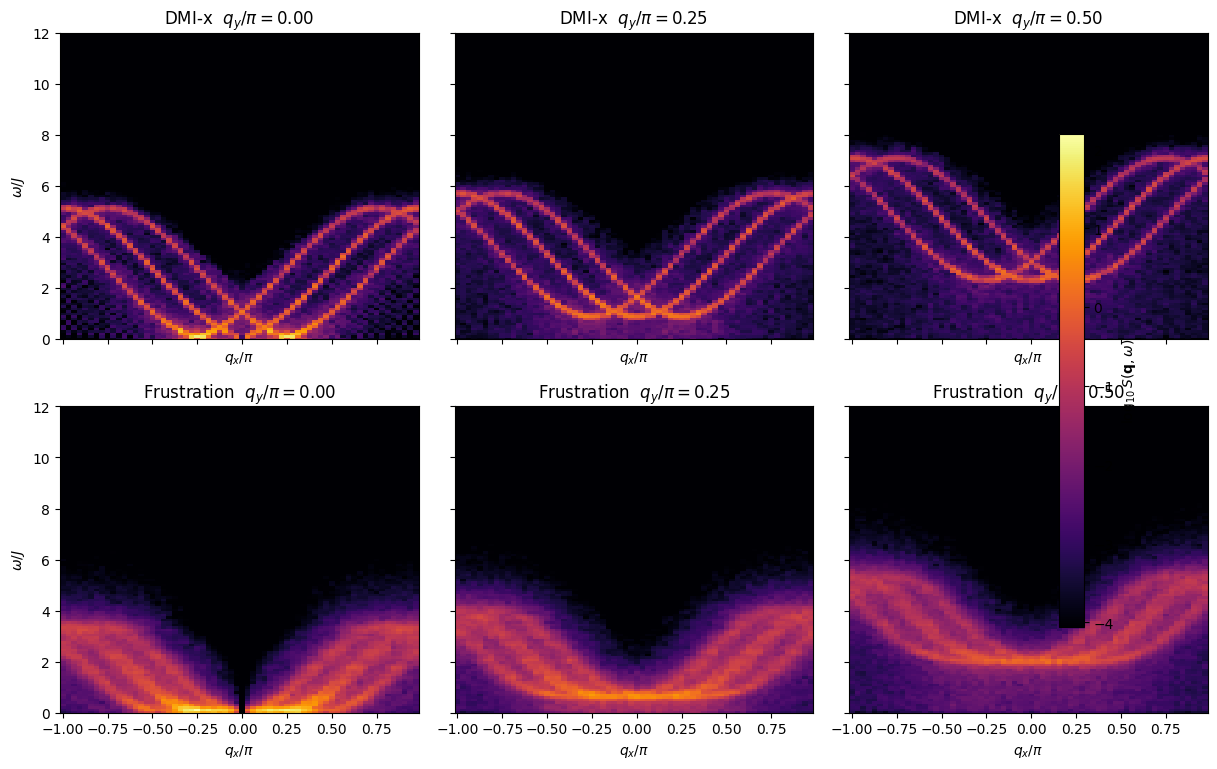

In [8]:
ky_targets = [0.0, np.pi / 4, np.pi / 2]
ky_positions = [np.argmin(np.abs(qy - val)) for val in ky_targets]

vmax_omega = 12.0
vmin = min(np.log10(np.max(S_dmi) + 1e-12), np.log10(np.max(S_fr) + 1e-12)) - 6
vmax = max(np.log10(np.max(S_dmi) + 1e-12), np.log10(np.max(S_fr) + 1e-12))

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)

for row, (model, spectrum) in enumerate([
    ("DMI-x", S_dmi),
    ("Frustration", S_fr)
]):
    for col, iy in enumerate(ky_positions):
        ax = axes[row, col]
        im = ax.pcolormesh(
            qx / np.pi,
            omega,
            np.log10(spectrum[:, :, iy] + 1e-12),
            cmap="inferno",
            vmin=vmin,
            vmax=vmax,
            shading="auto"
        )
        ax.set_title(f"{model}  $q_y/\pi={qy[iy]/np.pi:.2f}$")
        ax.set_ylim(0, vmax_omega)
        ax.set_xlabel(r"$q_x/\pi$")
        if col == 0:
            ax.set_ylabel(r"$\omega/J$")

fig.colorbar(im, ax=axes.ravel().tolist(), label=r"$\log_{10} S(\mathbf{q},\omega)$", shrink=0.80, pad=0.02)
fig.subplots_adjust(left=0.07, right=0.89, bottom=0.08, top=0.93, wspace=0.10, hspace=0.22)
fig.savefig(OUTPUT / "asd_spectra_qx_ky_slices.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_spectra_qx_ky_slices.png", dpi=350, bbox_inches="tight")
plt.show()

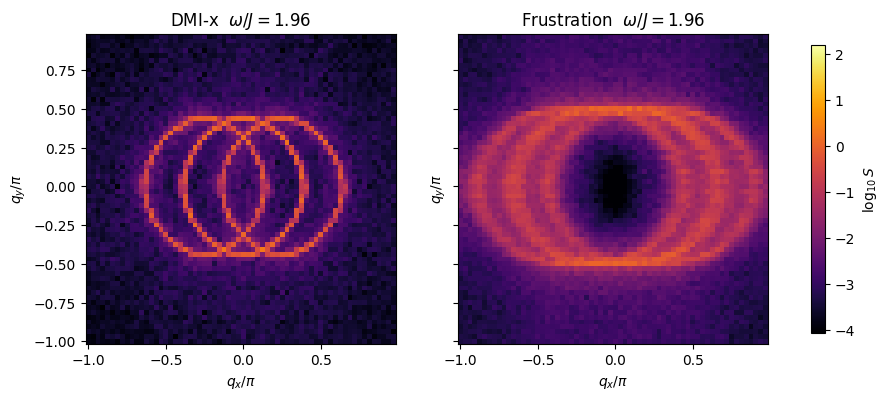

In [9]:
energy_target = 2.0
iw = np.argmin(np.abs(omega - energy_target))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

for ax, model, spectrum in zip(
    axes,
    ["DMI-x", "Frustration"],
    [S_dmi, S_fr]
):
    im = ax.pcolormesh(
        qx / np.pi,
        qy / np.pi,
        np.log10(spectrum[iw].T + 1e-12),
        shading="auto", cmap="inferno", vmin=vmin, vmax=vmax
    )
    ax.set_title(f"{model}  $\omega/J={omega[iw]:.2f}$")
    ax.set_xlabel(r"$q_x/\pi$")
    ax.set_ylabel(r"$q_y/\pi$")
    ax.set_aspect("equal")

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.83, label=r"$\log_{10} S$")
fig.savefig(OUTPUT / "asd_constant_energy_maps.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_constant_energy_maps.png", dpi=350, bbox_inches="tight")
plt.show()

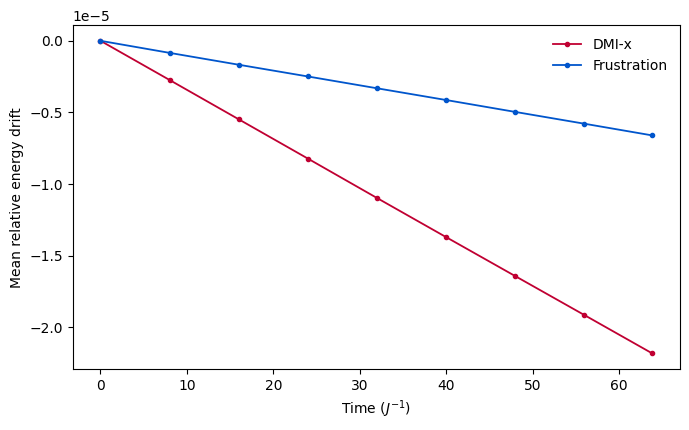

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.4))

for model, times, energies, color in [
    ("DMI-x", t_energy_dmi, energy_dmi, "#C00032"),
    ("Frustration", t_energy_fr, energy_fr, "#0055CC")
]:
    relative = (energies - energies[0]) / np.maximum(np.abs(energies[0]), 1e-10)
    ax.plot(times, relative.mean(axis=1), marker="o", ms=3, lw=1.3, color=color, label=model)

ax.set_xlabel(r"Time ($J^{-1}$)")
ax.set_ylabel(r"Mean relative energy drift")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / "asd_energy_conservation.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_energy_conservation.png", dpi=350, bbox_inches="tight")
plt.show()

In [11]:
np.savez_compressed(
    OUTPUT / "asd_dynamical_structure_factor_T0p1.npz",
    qx=qx,
    qy=qy,
    omega=omega,
    S_dmi=S_dmi,
    S_frustration=S_fr,
    temperature=T_ASD,
    dt=DT_ASD,
    sample_every=SAMPLE_EVERY_ASD,
    n_samples=N_SAMPLES_ASD,
    n_replicas=N_REPLICAS_ASD,
    J=J_asd,
    D=D_asd,
    J2=J2_asd,
    B_z=Bz_asd,
    energy_time_dmi=t_energy_dmi,
    energy_dmi=energy_dmi,
    energy_time_frustration=t_energy_fr,
    energy_frustration=energy_fr
)

print("Saved:", OUTPUT / "asd_dynamical_structure_factor_T0p1.npz")
print("Frequency grid:", len(omega), "Lattice:", len(qx), "x", len(qy))

Saved: /home/senji77/akhyar/research/notebooks/ANSW/asd_2d_results/asd_dynamical_structure_factor_T0p1.npz
Frequency grid: 256 Lattice: 64 x 64


In [12]:

from pathlib import Path
import numpy as np

file = Path("asd_2d_results/asd_dynamical_structure_factor_T0p1.npz")

with np.load(file) as data:
    for model, key in [
        ("DMI-x", "energy_dmi"),
        ("Frustration", "energy_frustration")
    ]:
        energies = data[key]

        drift = np.max(
            np.abs(energies - energies[0])
            / np.maximum(np.abs(energies[0]), 1e-10)
        )

        print(f"{model} max relative energy drift: {drift:.8e}")

    print("Temperature:", data["temperature"])
    print("Replicas:", data["n_replicas"])
    print("Frequency resolution:", data["omega"][1] - data["omega"][0])


DMI-x max relative energy drift: 2.26874374e-05
Frustration max relative energy drift: 6.67630497e-06
Temperature: 0.1
Replicas: 4
Frequency resolution: 0.09817477042468103
